In [1]:
import pandas as pd


In [3]:

import os
import zipfile
import urllib.request
import pandas as pd

# UCI SMS Spam Collection dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Create dataset directory
os.makedirs("/content/dataset", exist_ok=True)

zip_path = "/content/dataset/sms_spam_collection.zip"
file_path = "/content/dataset/SMSSpamCollection"

# Download only if the dataset is not already available
if not os.path.exists(file_path):
    print("Downloading SMS Spam Collection dataset...")

    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extract("SMSSpamCollection", "/content/dataset")

    print("Dataset downloaded successfully!")

# Load dataset
message = pd.read_csv(
    file_path,
    sep="\t",
    names=["label", "message"],
    header=None
)

print("Dataset loaded successfully!")
print("Dataset shape:", message.shape)
print("\nClass distribution:")
print(message["label"].value_counts())

message.head()


Dataset downloaded successfully!
Dataset loaded successfully!
Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
message

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [5]:
message.shape

(5572, 2)

In [6]:
message['message'].loc[100]

"Please don't text me anymore. I have nothing else to say."

In [35]:
from gensim.models import Word2Vec

In [7]:
#data cleaning
import re
import nltk
nltk.download('stopwords')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [34]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from gensim.models import Word2Vec

# Features and target
X_text = corpus
y = message['label'].values

# Split dataset into training and testing sets
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=0,
    stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

Training samples: 4457
Testing samples: 1115


In [8]:
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
ps=PorterStemmer()


In [9]:

# Import required libraries
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

# Download NLTK stopwords
nltk.download('stopwords')

# Initialize preprocessing tools
ps = PorterStemmer()
stop_words = set(stopwords.words('english'))

# Text preprocessing function
def preprocess_text(text):

    # Remove special characters and numbers
    review = re.sub('[^a-zA-Z]', ' ', str(text))

    # Convert to lowercase
    review = review.lower()

    # Tokenize
    review = review.split()

    # Remove stopwords and apply stemming
    review = [
        ps.stem(word)
        for word in review
        if word not in stop_words
    ]

    return ' '.join(review)


# Apply preprocessing to all SMS messages
corpus = message['message'].apply(preprocess_text).tolist()

print("Preprocessing completed!")
print("Total messages:", len(corpus))
print("Sample original message:", message['message'].iloc[0])
print("Sample processed message:", corpus[0])


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Preprocessing completed!
Total messages: 5572
Sample original message: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Sample processed message: go jurong point crazi avail bugi n great world la e buffet cine got amor wat


In [32]:

from sklearn.model_selection import train_test_split

X_text = corpus
y = message['label'].values

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=0,
    stratify=y
)

print("Training:", len(X_train_text))
print("Testing:", len(X_test_text))


Training: 4457
Testing: 1115


In [ ]:
corpus

['go jurong point crazi avail bugi n great world la e buffet cine got amor wat',
 'ok lar joke wif u oni',
 'free entri wkli comp win fa cup final tkt st may text fa receiv entri question std txt rate c appli',
 'u dun say earli hor u c alreadi say',
 'nah think goe usf live around though',
 'freemsg hey darl week word back like fun still tb ok xxx std chg send rcv',
 'even brother like speak treat like aid patent',
 'per request mell mell oru minnaminungint nurungu vettam set callertun caller press copi friend callertun',
 'winner valu network custom select receivea prize reward claim call claim code kl valid hour',
 'mobil month u r entitl updat latest colour mobil camera free call mobil updat co free',
 'gonna home soon want talk stuff anymor tonight k cri enough today',
 'six chanc win cash pound txt csh send cost p day day tsandc appli repli hl info',
 'urgent week free membership prize jackpot txt word claim c www dbuk net lccltd pobox ldnw rw',
 'search right word thank breather

In [31]:

# Bag of Words - Feature Extraction

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

cv = CountVectorizer(
    max_features=2500,
    binary=True,
    ngram_range=(2, 2)
)

X_train_bow = cv.fit_transform(X_train_text)
X_test_bow = cv.transform(X_test_text)

# Train Naive Bayes
bow_model = MultinomialNB()
bow_model.fit(X_train_bow, y_train)

# Prediction
bow_predictions = bow_model.predict(X_test_bow)

# Evaluation
print("Bag of Words Accuracy:",
      accuracy_score(y_test, bow_predictions))

print(classification_report(
    y_test,
    bow_predictions,
    target_names=['Ham', 'Spam']
))



Bag of Words Accuracy: 0.9668161434977578
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       0.99      0.76      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd


In [18]:
tfidf = TfidfVectorizer(
    max_features=2500,
    ngram_range=(1, 2),
    binary=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

tfidf_model = MultinomialNB()
tfidf_model.fit(X_train_tfidf, y_train)

tfidf_predictions = tfidf_model.predict(X_test_tfidf)

print("TF-IDF Accuracy:",
      accuracy_score(y_test, tfidf_predictions))

print(classification_report(
    y_test,
    tfidf_predictions,
    target_names=['Ham', 'Spam']
))

TF-IDF Accuracy: 0.9721973094170404
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.93      1115
weighted avg       0.97      0.97      0.97      1115



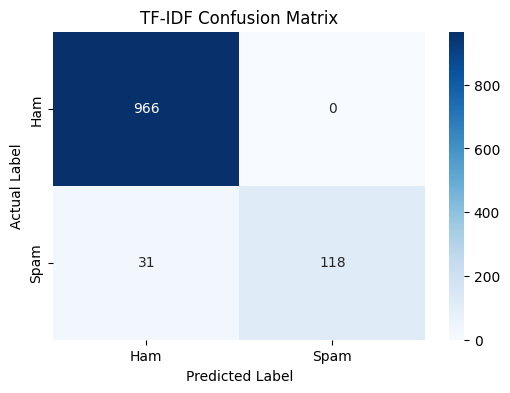

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, tfidf_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('TF-IDF Confusion Matrix')

plt.show()

In [20]:
results = pd.DataFrame({
    'Model': ['Bag of Words', 'TF-IDF'],
    'Accuracy': [
        accuracy_score(y_test, bow_predictions),
        accuracy_score(y_test, tfidf_predictions)
    ]
})

results['Accuracy (%)'] = results['Accuracy'] * 100

print(results)

          Model  Accuracy  Accuracy (%)
0  Bag of Words  0.966816     96.681614
1        TF-IDF  0.972197     97.219731


In [22]:
# Tokenize training and testing messages
X_train_tokens = [text.split() for text in X_train_text]
X_test_tokens = [text.split() for text in X_test_text]

# Train Word2Vec using training messages only
word2vec_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    seed=42,
    epochs=20
)

print("Word2Vec model trained successfully!")
print("Vocabulary size:", len(word2vec_model.wv))

Word2Vec model trained successfully!
Vocabulary size: 2840


In [23]:
def get_document_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


# Convert training and testing messages
X_train_w2v = np.array([
    get_document_vector(tokens, word2vec_model)
    for tokens in X_train_tokens
])

X_test_w2v = np.array([
    get_document_vector(tokens, word2vec_model)
    for tokens in X_test_tokens
])

print("Training features:", X_train_w2v.shape)
print("Testing features:", X_test_w2v.shape)

Training features: (4457, 100)
Testing features: (1115, 100)


In [24]:
def get_document_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


# Convert training and testing messages
X_train_w2v = np.array([
    get_document_vector(tokens, word2vec_model)
    for tokens in X_train_tokens
])

X_test_w2v = np.array([
    get_document_vector(tokens, word2vec_model)
    for tokens in X_test_tokens
])

print("Training features:", X_train_w2v.shape)
print("Testing features:", X_test_w2v.shape)

Training features: (4457, 100)
Testing features: (1115, 100)


Word2vec implementation

In [25]:
# Train Logistic Regression
word2vec_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

word2vec_classifier.fit(X_train_w2v, y_train)

# Predictions
word2vec_predictions = word2vec_classifier.predict(X_test_w2v)

# Evaluation
print(
    "Word2Vec Accuracy:",
    accuracy_score(y_test, word2vec_predictions)
)

print("\nClassification Report:")

print(classification_report(
    y_test,
    word2vec_predictions,
    target_names=['Ham', 'Spam']
))

Word2Vec Accuracy: 0.9650224215246637

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      0.99      0.98       966
        Spam       0.90      0.83      0.86       149

    accuracy                           0.97      1115
   macro avg       0.94      0.91      0.92      1115
weighted avg       0.96      0.97      0.96      1115



In [29]:


def predict_sms(sms, model_type="tfidf"):

    # Preprocess the new SMS
    cleaned_sms = preprocess_text(sms)

    if model_type == "bow":
        features = cv.transform([cleaned_sms])
        prediction = bow_model.predict(features)[0]

    elif model_type == "tfidf":
        features = tfidf.transform([cleaned_sms])
        prediction = tfidf_model.predict(features)[0]

    elif model_type == "word2vec":
        tokens = cleaned_sms.split()
        features = get_document_vector(tokens, word2vec_model)
        features = np.array([features])
        prediction = word2vec_classifier.predict(features)[0]

    else:
        raise ValueError("Choose bow, tfidf, or word2vec")

    return "Spam" if prediction == "spam" else "Ham"


# Test with a new SMS
new_sms = input("Enter your SMS message: ")

result = predict_sms(new_sms, model_type="tfidf")

print("Prediction:", result)


Enter your SMS message: happy holiday package
Prediction: Ham
